<a href="https://colab.research.google.com/github/CamilaAg-05/Data_Analytics_3-Camila_Aguado/blob/main/notebooks/S12_ML_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [2]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [3]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [4]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [5]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [6]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [7]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [8]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 1
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 01 | Semilla: 1001
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 9e0cf0664d9d


/tmp/ipykernel_2089/3139553389.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1, 0].boxplot([train.loc[train['is_late'] == 0, 'dias_prometidos'],


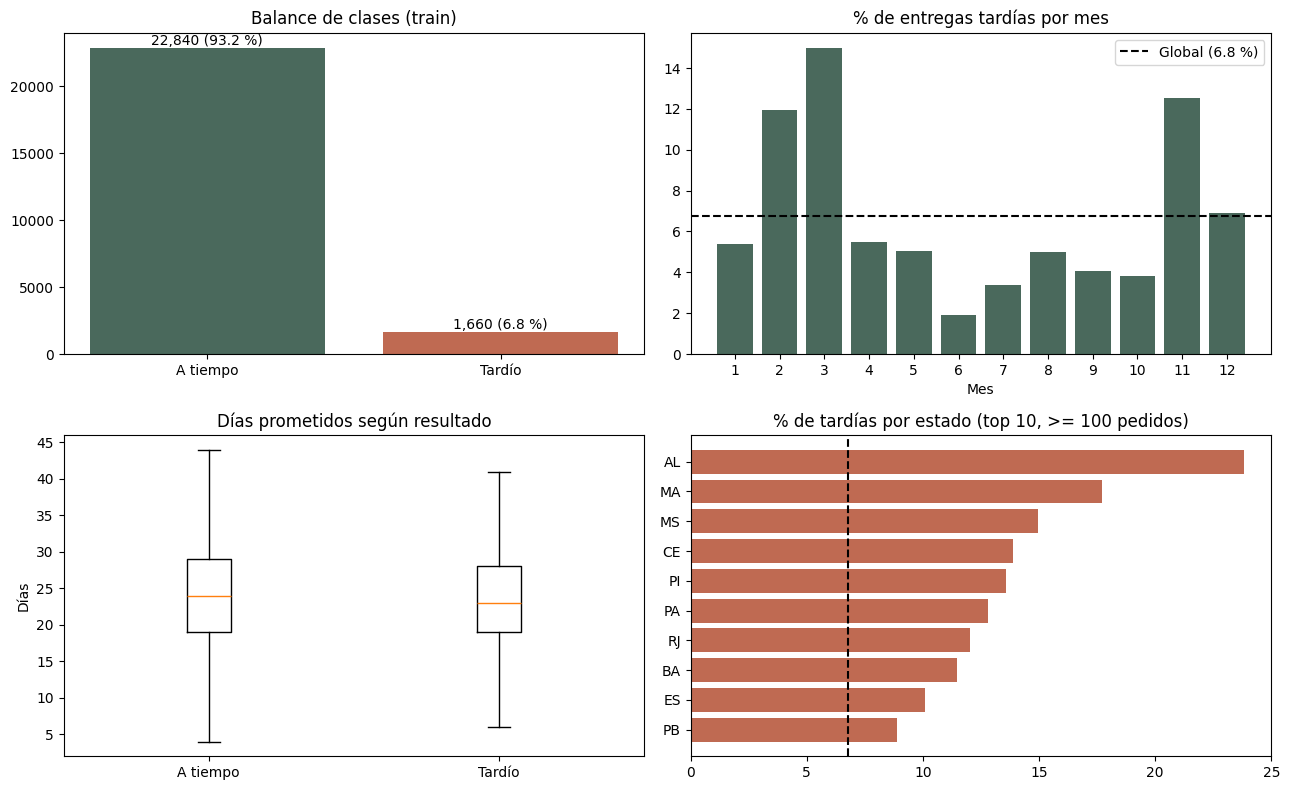

In [28]:
import matplotlib.pyplot as plt

# Exploración del dataset propio (solo entrenamiento)
tasa_global = 100 * train['is_late'].mean()
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# 1. Balance de clases
conteo = train['is_late'].value_counts().sort_index()
b = ax[0, 0].bar(['A tiempo', 'Tardío'], conteo.values, color=['#4a695c', '#bf6a52'])
ax[0, 0].bar_label(b, labels=[f'{v:,} ({100*v/len(train):.1f} %)' for v in conteo.values])
ax[0, 0].set_title('Balance de clases (train)')

# 2. % de entregas tardías por mes de compra (tasa real, no error del modelo)
tasa_mes = 100 * train.groupby('mes_compra')['is_late'].mean()
ax[0, 1].bar(tasa_mes.index.astype(str), tasa_mes.values, color='#4a695c')
ax[0, 1].axhline(tasa_global, color='k', ls='--', label=f'Global ({tasa_global:.1f} %)')
ax[0, 1].set_title('% de entregas tardías por mes')
ax[0, 1].set_xlabel('Mes'); ax[0, 1].legend()

# 3. Plazo prometido según si llegó tarde o no
ax[1, 0].boxplot([train.loc[train['is_late'] == 0, 'dias_prometidos'],
                  train.loc[train['is_late'] == 1, 'dias_prometidos']],
                 labels=['A tiempo', 'Tardío'], showfliers=False)
ax[1, 0].set_title('Días prometidos según resultado')
ax[1, 0].set_ylabel('Días')

# 4. % de tardías por estado (solo estados con >= 100 pedidos)
g = train.groupby('customer_state')['is_late'].agg(['size', 'mean'])
g = g[g['size'] >= 100].sort_values('mean').tail(10)
ax[1, 1].barh(g.index, 100 * g['mean'], color='#bf6a52')
ax[1, 1].axvline(tasa_global, color='k', ls='--')
ax[1, 1].set_title('% de tardías por estado (top 10, >= 100 pedidos)')

plt.tight_layout(); plt.show()

en este dataset se ve que solo el 6,8 % de los pedidos (1.660 de 24.500) llega tarde.

También se ve que los retrasos no son parejos durante el año, ya que, suben en febrero, marzo y noviembre (12 a 15 %) y bajan mucho en junio (cerca de 2 %). Los días prometidos son casi iguales en pedidos puntuales y tardíos (24 y 23 días aprox.), así que esa variable por sí sola ayuda poco. Por estado, Alagoas (cerca de 24 %) y Maranhão (cerca de 18 %) tienen más retrasos, y los estados con más pedidos (SP, MG) no aparecen en el top 10.

## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [9]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


In [10]:
# variables disponibles
print("Variables disponibles en el conjunto de entrenamiento:")
print(X_train.columns.tolist())

print("\nDimensiones de X_train:")
print(X_train.shape)

print("\nPrimeros registros:")
display(X_train.head())

print("\nTipos de variables:")
display(X_train.dtypes.to_frame("tipo"))

Variables disponibles en el conjunto de entrenamiento:
['dias_prometidos', 'mes_compra', 'dia_semana_compra', 'dia_mes_compra', 'hora_compra', 'compra_fin_semana', 'valor_productos', 'valor_flete', 'precio_maximo', 'cantidad_items', 'cantidad_productos', 'cantidad_vendedores', 'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3', 'fotos_promedio', 'descripcion_promedio', 'nombre_promedio', 'numero_pagos', 'cuotas_maximas', 'valor_pagado', 'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete', 'customer_state', 'estado_vendedor', 'categoria_principal', 'tipo_pago_principal']

Dimensiones de X_train:
(24500, 28)

Primeros registros:


,dias_prometidos,mes_compra,dia_semana_compra,dia_mes_compra,hora_compra,compra_fin_semana,valor_productos,valor_flete,precio_maximo,cantidad_items,...,numero_pagos,cuotas_maximas,valor_pagado,vendedor_mismo_estado,vendedor_misma_ciudad,proporcion_flete,customer_state,estado_vendedor,categoria_principal,tipo_pago_principal
34937,26,4,3,19,12,0,86.00,20.86,86.00,1,...,1.0,4.0,106.86,0,0,0.195209,ES,SP,bed_bath_table,credit_card
8328,22,11,6,12,12,1,99.00,14.44,99.00,1,...,1.0,6.0,113.44,0,0,0.127292,DF,SP,sports_leisure,credit_card
17912,30,6,2,28,11,0,29.99,34.15,29.99,1,...,1.0,2.0,64.14,0,0,0.532429,AL,SP,telephony,credit_card
25636,36,7,2,26,12,0,19.99,15.10,19.99,1,...,1.0,3.0,35.09,0,0,0.430322,RJ,SP,fixed_telephony,credit_card
21684,31,2,4,2,13,0,98.00,16.94,98.00,1,...,1.0,10.0,129.89,0,0,0.147381,MG,SP,sin_categoria,credit_card



Tipos de variables:


,tipo
dias_prometidos,int64
mes_compra,int32
dia_semana_compra,int32
dia_mes_compra,int32
hora_compra,int32
compra_fin_semana,int64
valor_productos,float64
valor_flete,float64
precio_maximo,float64
cantidad_items,int64


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [11]:
# TODO 1. Entrene el modelo y genere predicciones.

# las dos opciones y muestra sus resultados para comparar
for pc in [None, 'balanced']:
    m = make_pipeline(preprocesamiento,
                      LogisticRegression(class_weight=pc, max_iter=1000))
    m.fit(X_train, y_train)          # entrena solo con train
    p = m.predict(X_valid)           # predice sobre validación
    tn, fp, fn, tp = confusion_matrix(y_valid, p).ravel()
    print(f"class_weight={pc}: "
          f"Accuracy={accuracy_score(y_valid, p):.3f} "
          f"Precision={precision_score(y_valid, p, zero_division=0):.3f} "
          f"Recall={recall_score(y_valid, p):.3f} "
          f"F1={f1_score(y_valid, p, zero_division=0):.3f} "
          f"| FP={fp} FN={fn} Costo=R$ {8*fp + 35*fn}")

# Opción elegida
peso_clases = 'balanced'

modelo = make_pipeline(preprocesamiento,
                       LogisticRegression(class_weight=peso_clases, max_iter=1000))
modelo.fit(X_train, y_train)
pred = modelo.predict(X_valid)

print("\nElegido:", peso_clases, "| Predicciones:", len(pred))

class_weight=None: Accuracy=0.933 Precision=1.000 Recall=0.003 F1=0.006 | FP=0 FN=354 Costo=R$ 12390
class_weight=balanced: Accuracy=0.669 Precision=0.121 Recall=0.623 F1=0.203 | FP=1606 FN=134 Costo=R$ 17538

Elegido: balanced | Predicciones: 5250


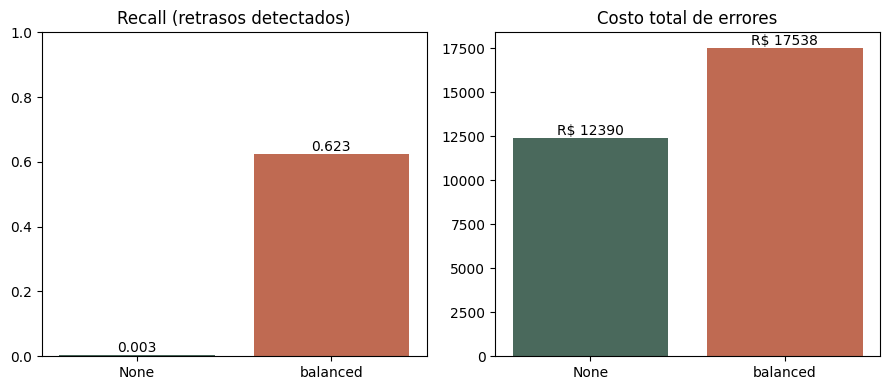

In [12]:
import matplotlib.pyplot as plt

# Valores de validación obtenidos en la Actividad 1 (umbral 0.5)
nombres = ['None', 'balanced']
recall  = [0.003, 0.623]
costo   = [12390, 17538]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))

# Recall: proporción de retrasos reales detectados
b1 = ax[0].bar(nombres, recall, color=['#4a695c', '#bf6a52'])
ax[0].bar_label(b1, fmt='%.3f')
ax[0].set_ylim(0, 1)
ax[0].set_title('Recall (retrasos detectados)')

# Costo total de errores con R$ 8 por FP y R$ 35 por FN
b2 = ax[1].bar(nombres, costo, color=['#4a695c', '#bf6a52'])
ax[1].bar_label(b2, fmt='R$ %d')
ax[1].set_title('Costo total de errores')

plt.tight_layout(); plt.show()

Se elige `class_weight='balanced'` porque es la única configuración que cumple el objetivo del modelo, detectar entregas tardías: con `None` el Recall es 0,003 (1 de 355 retrasos) y el costo (R$ 12.390) es prácticamente el del modelo de referencia (R$ 12.425), es decir, equivale a no predecir; con `balanced` el Recall sube a 0,623 y el F1 a 0,203. La Precision baja a 0,121 y el costo sube a R$ 17.538 por 1.606 falsas alarmas

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [13]:
# TODO 2. Calcule las métricas y muestre la matriz de confusión.

# Probabilidad estimada de entrega tardía por pedido; insumo de ROC-AUC y AP.
proba = modelo.predict_proba(X_valid)[:, 1]

medidas = {
    'accuracy':  accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall':    recall_score(y_valid, pred),
    'f1':        f1_score(y_valid, pred, zero_division=0),
    'roc_auc':   roc_auc_score(y_valid, proba),   # calculado con probabilidades
    'ap':        average_precision_score(y_valid, proba),
}
print({k: round(v, 4) for k, v in medidas.items()})

{'accuracy': 0.6686, 'precision': 0.121, 'recall': 0.6225, 'f1': 0.2026, 'roc_auc': np.float64(0.7075), 'ap': np.float64(0.16)}


de cada 10 pedidos que de verdad llegan tarde, el modelo encuentra 6. Pero de cada 8 alertas que lanza, solo 1 es cierta.

In [14]:
# Prevalencia en validación: valor de AP de un clasificador aleatorio (referencia).
print('Prevalencia (AP del azar):', round(y_valid.mean(), 4))

# Matriz de confusión: [[TN, FP], [FN, TP]]
print(confusion_matrix(y_valid, pred))

Prevalencia (AP del azar): 0.0676
[[3289 1606]
 [ 134  221]]


solo 7 de cada 100 pedidos llegan tarde.

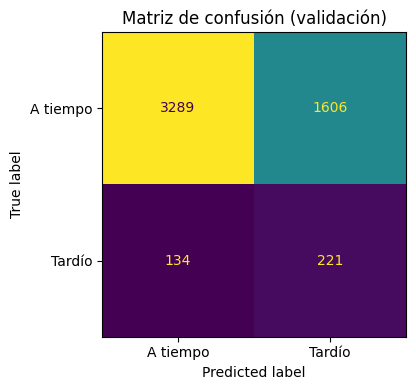

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matriz de confusión del modelo elegido (class_weight='balanced')
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_valid, pred, ax=ax, colorbar=False, display_labels=['A tiempo', 'Tardío'])
ax.set_title('Matriz de confusión (validación)')
plt.tight_layout(); plt.show()

el modelo detectó 221 retrasos, pero generó 1.606 falsas alarmas.

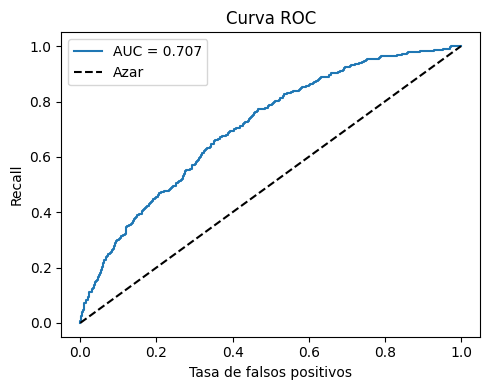

In [16]:
from sklearn.metrics import roc_curve

# Curva ROC: Recall vs tasa de falsos positivos en todos los umbrales
fpr, tpr, _ = roc_curve(y_valid, proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {medidas['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Recall')
plt.title('Curva ROC'); plt.legend()
plt.tight_layout(); plt.show()

el modelo distingue pedidos riesgosos de los normales mejor que el azar, pero no de forma contundente.

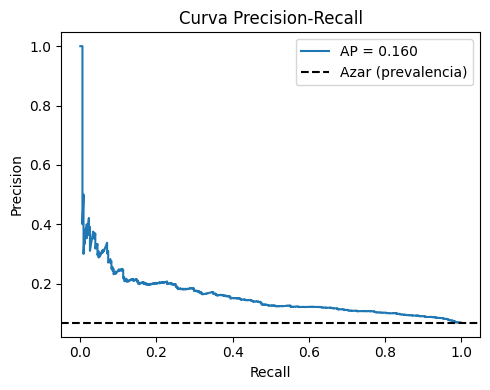

In [17]:
from sklearn.metrics import precision_recall_curve

# Curva Precision-Recall: línea punteada = prevalencia (desempeño aleatorio)
prec, rec, _ = precision_recall_curve(y_valid, proba)
plt.figure(figsize=(5, 4))
plt.plot(rec, prec, label=f"AP = {medidas['ap']:.3f}")
plt.axhline(y_valid.mean(), color='k', ls='--', label='Azar (prevalencia)')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Curva Precision-Recall'); plt.legend()
plt.tight_layout(); plt.show()

### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [18]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
# Pedidos, errores y % de error por mes de compra.
por_mes = analisis.groupby('mes_compra').agg(
    pedidos=('error', 'size'),
    errores=('error', 'sum'),
    tasa_error_pct=('error', lambda s: 100 * s.mean())
).round(2)

# Pedidos, errores y % de error por estado del cliente.
por_estado = analisis.groupby('customer_state').agg(
    pedidos=('error', 'size'),
    errores=('error', 'sum'),
    tasa_error_pct=('error', lambda s: 100 * s.mean())
).round(2)

print('Error global (%):', round(100 * analisis['error'].mean(), 2))
print('\nPor mes de compra (ordenado por tasa de error):')
display(por_mes.sort_values('tasa_error_pct', ascending=False))
print('\nPor estado del cliente (ordenado por tasa de error):')
display(por_estado.sort_values('tasa_error_pct', ascending=False))

Error global (%): 33.14

Por mes de compra (ordenado por tasa de error):


,pedidos,errores,tasa_error_pct
mes_compra,,,
8,603,264,43.78
3,562,242,43.06
5,532,207,38.91
7,543,201,37.02
2,422,142,33.65
9,237,76,32.07
10,226,71,31.42
1,421,130,30.88
4,530,159,30.00



Por estado del cliente (ordenado por tasa de error):


,pedidos,errores,tasa_error_pct
customer_state,,,
RR,3,3,100.00
SE,15,14,93.33
PA,45,35,77.78
PI,32,22,68.75
AL,25,17,68.00
MS,45,30,66.67
ES,124,77,62.10
RJ,682,423,62.02
MA,34,21,61.76


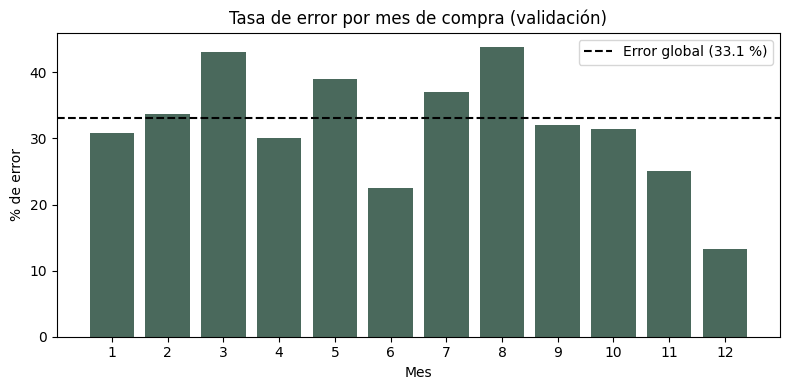

In [21]:
import matplotlib.pyplot as plt

tasa_global = 100 * analisis['error'].mean()

# Barras = % de error por mes; línea punteada = error global.
plt.figure(figsize=(8, 4))
plt.bar(por_mes.index.astype(str), por_mes['tasa_error_pct'], color='#4a695c')
plt.axhline(tasa_global, color='k', ls='--', label=f'Error global ({tasa_global:.1f} %)')
plt.title('Tasa de error por mes de compra (validación)')
plt.xlabel('Mes'); plt.ylabel('% de error'); plt.legend()
plt.tight_layout(); plt.show()

**Análisis por mes:** El error global es 33,1 %. Fallan más agosto (43,8 %, 603 pedidos) y marzo (43,1 %, 562 pedidos), seguidos de mayo (38,9 %) y julio (37,0 %). Falla menos diciembre (13,2 %, 272 pedidos). Esta diferencia de más de 30 puntos sugiere que el modelo no se comporta igual todo el año, posiblemente por un efecto estacional que no captura (hipótesis). Como casi todo el error son falsas alarmas, un error alto significa más alertas innecesarias, no necesariamente más retrasos reales.

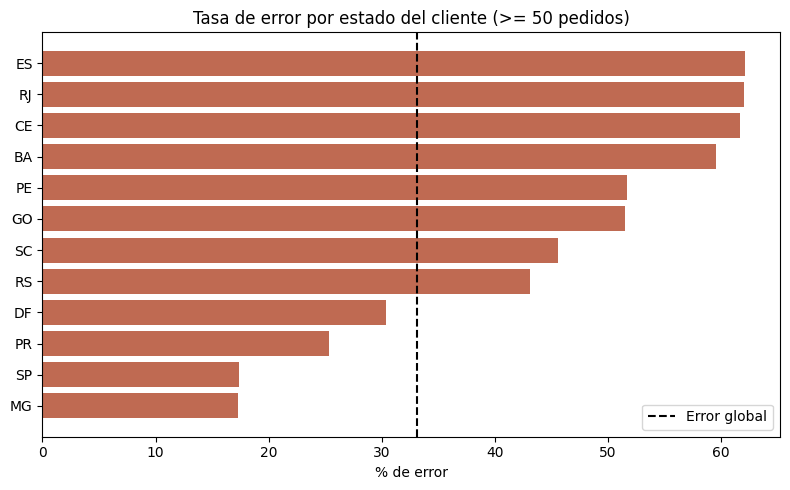

In [22]:
# Solo estados con >= 50 pedidos; con menos, la tasa varía mucho por azar.
est = por_estado[por_estado['pedidos'] >= 50].sort_values('tasa_error_pct')

plt.figure(figsize=(8, 5))
plt.barh(est.index, est['tasa_error_pct'], color='#bf6a52')
plt.axvline(tasa_global, color='k', ls='--', label='Error global')
plt.title('Tasa de error por estado del cliente (>= 50 pedidos)')
plt.xlabel('% de error'); plt.legend()
plt.tight_layout(); plt.show()

**Análisis por estado:** Solo se grafican estados con al menos 50 pedidos, para que las tasas sean confiables. Fallan más Espírito Santo (62,1 %), Río de Janeiro (62,0 %, 682 pedidos), Ceará (61,6 %) y Bahía (59,5 %), casi el doble del error global (33,1 %). Fallan menos Minas Gerais (17,3 %) y São Paulo (17,4 %, 2.191 pedidos). Río de Janeiro pesa más por su volumen: concentra 423 errores, cerca del 24 % del total.

### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [23]:
# TODO 4. Calcule el costo total con la matriz de confusión.

# Matriz de confusión: [[TN, FP], [FN, TP]]
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

# Costos del ejercicio: R$ 8 por falso positivo, R$ 35 por falso negativo.
costo_fp_fn = 8 * fp + 35 * fn

print(f'FP = {fp} -> R$ {8 * fp}')
print(f'FN = {fn} -> R$ {35 * fn}')
print(f'Costo total: R$ {costo_fp_fn}')

FP = 1606 -> R$ 12848
FN = 134 -> R$ 4690
Costo total: R$ 17538


**Análisis del costo:** Con el umbral de 0,5, el modelo `balanced` comete 1.606 falsas alarmas (12.848 reales) y 134 retrasos no detectados (4.690 reales), para un total de 17.538 reales. Cada retraso no detectado cuesta más (35 frente a 8), pero hay unas 12 veces más falsas alarmas, y por eso estas pesan el 73 % del costo.

In [24]:
# Modelo de referencia:
fn_ref = int(((pred_ref == 0) & (y_valid == 1)).sum())
costo_ref = 35 * fn_ref

print(f'Costo del modelo de referencia (Dummy): R$ {costo_ref}')
print(f'Costo del modelo balanced:              R$ {costo_fp_fn}')
print(f'Diferencia: R$ {costo_fp_fn - costo_ref}')

Costo del modelo de referencia (Dummy): R$ 12425
Costo del modelo balanced:              R$ 17538
Diferencia: R$ 5113


**Análisis frente al modelo de referencia:** No predecir nada cuesta 12.425 reales, y el modelo `balanced` cuesta 5.113 reales más (17.538). Detecta 221 retrasos, pero sus 1.606 falsas alarmas cuestan más de lo que ahorra. Para que alertar compense, la Precision debería superar 18,6 % y la del modelo es 12,1 %.

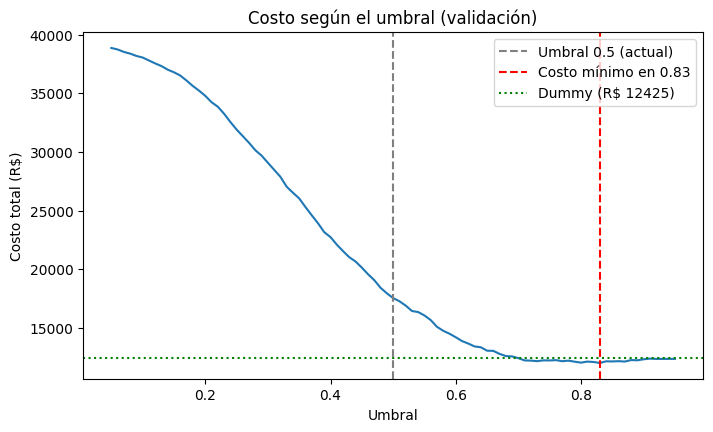

Umbral de menor costo: 0.83 -> R$ 12006


In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Costo total al variar el umbral de decisión sobre las probabilidades (proba).
umbrales = np.linspace(0.05, 0.95, 91)
costos = []
for u in umbrales:
    p_u = (proba >= u).astype(int)
    _, fp_u, fn_u, _ = confusion_matrix(y_valid, p_u).ravel()
    costos.append(8 * fp_u + 35 * fn_u)

u_opt = umbrales[int(np.argmin(costos))]

plt.figure(figsize=(8, 4.5))
plt.plot(umbrales, costos)
plt.axvline(0.5, color='gray', ls='--', label='Umbral 0.5 (actual)')
plt.axvline(u_opt, color='red', ls='--', label=f'Costo mínimo en {u_opt:.2f}')
plt.axhline(costo_ref, color='green', ls=':', label=f'Dummy (R$ {costo_ref})')
plt.xlabel('Umbral'); plt.ylabel('Costo total (R$)')
plt.title('Costo según el umbral (validación)')
plt.legend(); plt.show()

print(f'Umbral de menor costo: {u_opt:.2f} -> R$ {min(costos)}')

**Análisis del umbral:** El costo baja al subir el umbral: con valores bajos el modelo alerta casi todo y las falsas alarmas lo disparan (más de 38.000 reales en 0,05). El mínimo está en 0,83, con 12.006 reales, 5.532 menos que con 0,5. Pero solo mejora en 419 reales (3,4 %) al modelo de referencia (12.425 reales), porque con umbrales altos el modelo casi no alerta y se parece a no predecir. Esto indica que las 28 variables aportan poca señal (ROC-AUC 0,707; AP 0,160). Como el 0,83 se eligió sobre la misma validación

### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [26]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [27]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.07 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:

El modelo de referencia siempre predice "a tiempo", su exactitud es alta (0,932) pero no detecta ningún retraso (Recall 0, F1 0). La regresión logística con `class_weight=None` hace casi lo mismo (Recall 0,003, F1 0,006). Con `class_weight='balanced'`, la Accuracy baja a 0,669, pero detecta el 62 % de los retrasos (Recall 0,623, F1 0,203). Se elige `balanced` porque es la única opción que detecta entregas tardías, que es el objetivo. Su costo (R\$ 17.538) es mayor al de la referencia (R\$ 12.425) por las falsas alarmas.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:

El error global es 33,14 % y casi todo son falsas alarmas. Por mes, fallan más agosto (43,78 %) y marzo (43,06 %), y menos diciembre (13,24 %). Por estado, el caso importante es Río de Janeiro (62,02 %, 682 pedidos), que concentra el 24 % de los errores; São Paulo (17,39 %) y Minas Gerais (17,25 %) son los que menos fallan.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [ ]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)
